### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [2]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [3]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

# dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie1.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    # "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [4]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45476731.0,3767.520,107.049000,1.6195,-1.7959,13.5969,0.42274,0.24780,9.84059,-0.00239,0.00271,-0.00435,0.1260,0,A1,A
1,45476733.5,3767.520,107.049000,1.6197,-1.7954,13.5971,0.37197,0.22563,9.83939,-0.00394,0.00529,-0.00295,0.1260,0,A1,A
2,45476728.5,3767.520,107.048000,1.6192,-1.7961,13.5968,0.39457,0.25581,9.83537,-0.00354,0.00251,-0.00404,0.1260,0,A1,A
3,45476736.0,3767.520,107.049000,1.6196,-1.7955,13.5979,0.41483,0.22451,9.83531,-0.00540,0.00077,0.00153,0.1260,0,A1,A
4,45476726.0,3767.520,107.048000,1.6190,-1.7962,13.5968,0.39042,0.27895,9.82614,-0.00743,-0.00130,-0.00236,0.1260,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
290109,41563778.5,5512.852,10.355333,0.6512,-1.5795,-48.0806,-1.78920,0.16438,10.33153,-0.00936,-0.01235,-0.02487,33.9372,0,B4,B
290110,41563781.0,5512.875,11.012904,0.6481,-1.5840,-47.9881,-1.88369,-0.02342,10.76440,-0.00575,-0.00767,-0.02849,33.9372,0,B4,B
290111,41563783.5,5512.899,10.800525,0.6452,-1.5904,-47.8951,-1.92509,-0.06587,10.62556,-0.00451,-0.02198,-0.02490,33.9372,0,B4,B
290112,41563786.0,5512.922,10.374600,0.6427,-1.5977,-47.8027,-1.60182,0.24200,10.34438,-0.00214,-0.02739,-0.02887,33.9408,0,B4,B


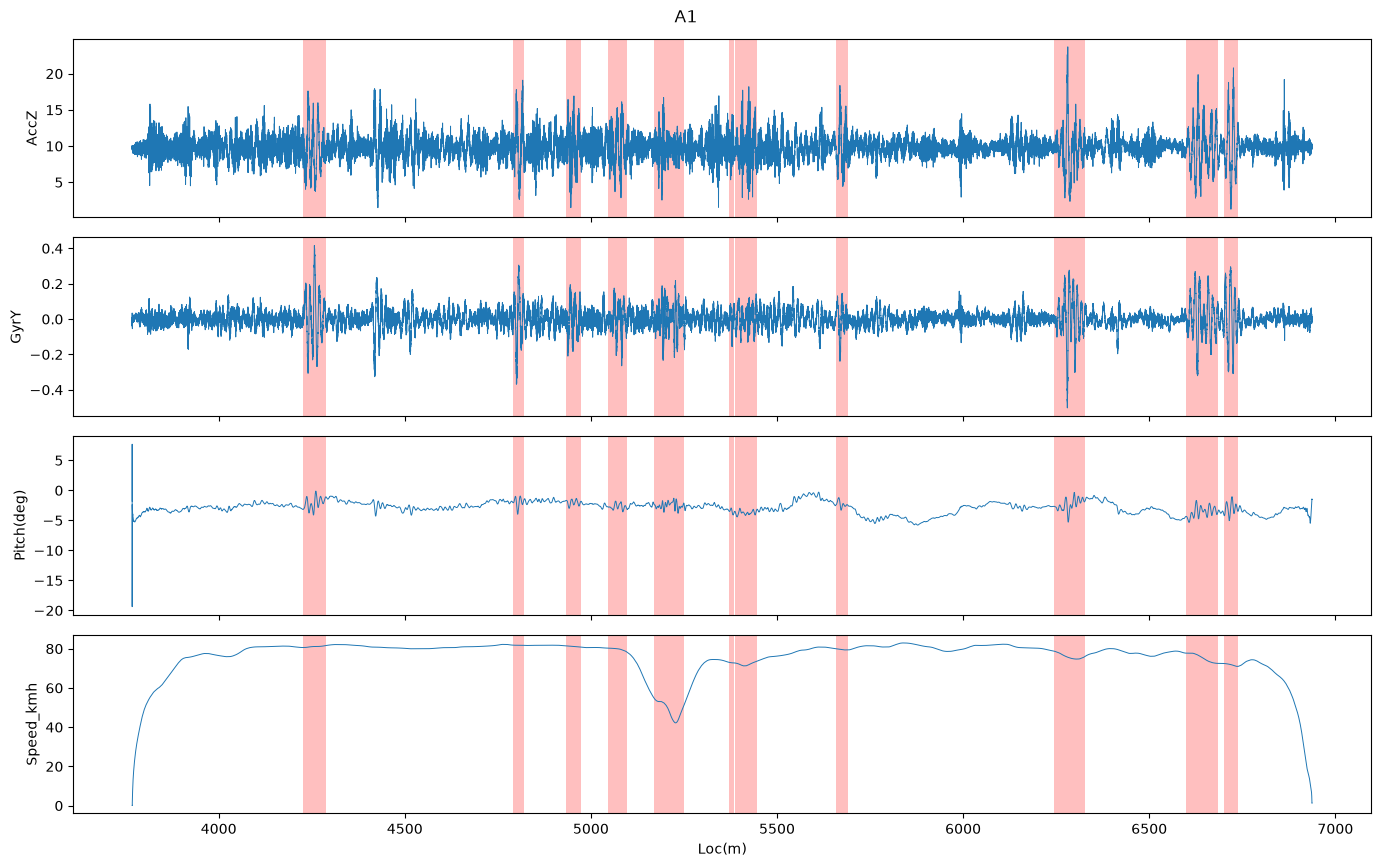

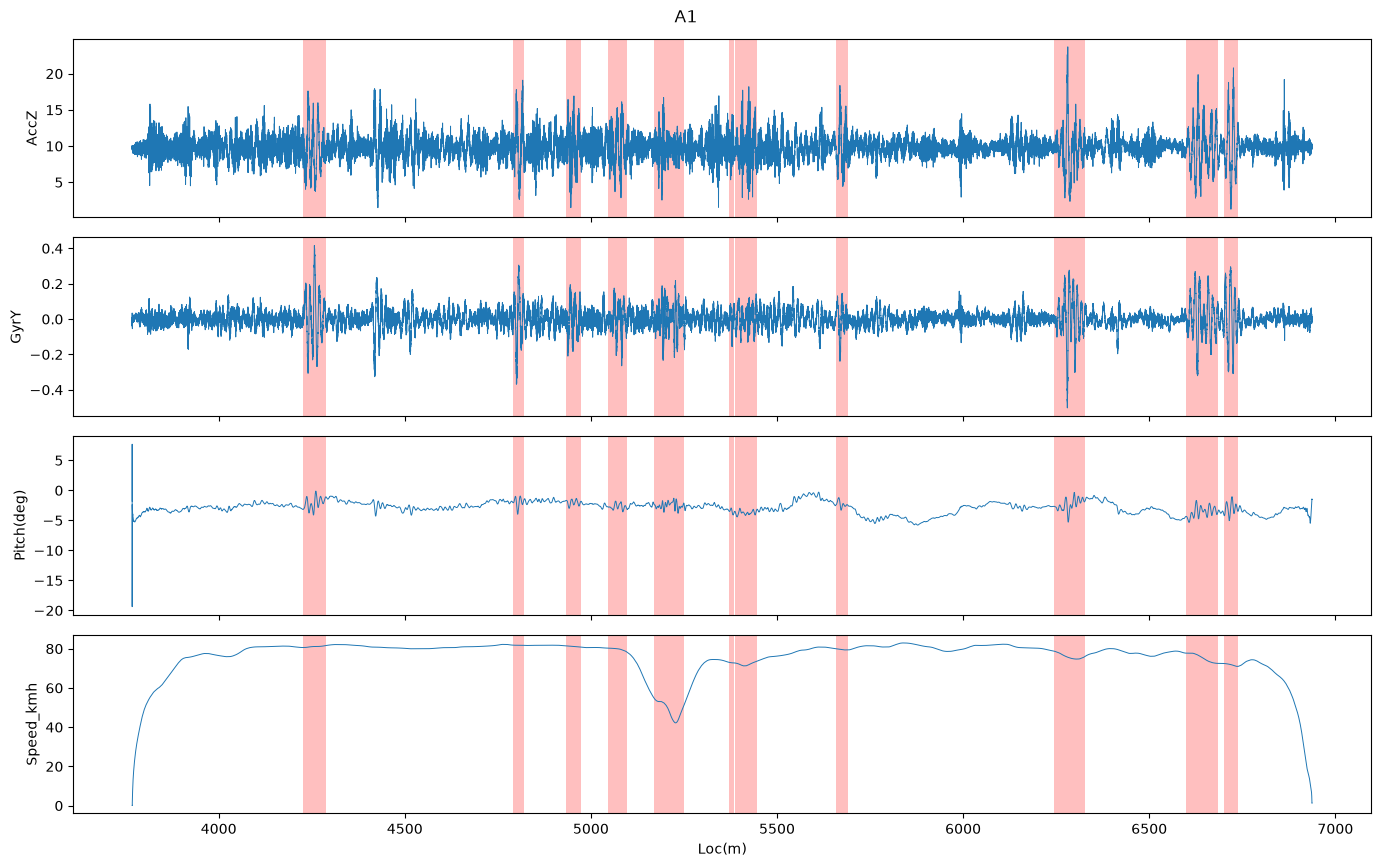

In [6]:


def plot_run(d, feats=("AccZ", "GyrY", "Pitch(deg)", "Speed_kmh"),
             x="Loc(m)", title=None, xlim=None):
    fig, axes = plt.subplots(len(feats), 1, figsize=(14, 2.2 * len(feats)),
                             sharex=True)
    for ax, f in zip(axes, feats):
        ax.plot(d[x], d[f], lw=0.7)
        ax.set_ylabel(f)

        # shade flagged bump regions
        flag = d["Frostbumps"].to_numpy() == 1
        edges = np.diff(flag.astype(int), prepend=0, append=0)
        starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0] - 1
        for s, e in zip(starts, ends):
            ax.axvspan(d[x].iloc[s], d[x].iloc[e], color="red", alpha=0.25, lw=0)

    axes[-1].set_xlabel(x)
    if xlim: axes[-1].set_xlim(xlim)
    fig.suptitle(title or "")
    fig.tight_layout()
    return fig

import numpy as np
plot_run(df[df.run_id == "A1"], title="A1")

In [29]:
feats = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
         "Pitch(deg)", "Roll(deg)", "Speed_kmh"]

stats = df.groupby("Frostbumps")[feats].agg(["mean", "std", "min", "median", "max"])
print(stats.T)   # transposed is easier to read

Frostbumps                 0          1
AccX       mean     0.498885   0.321744
           std      0.801845   0.789422
           min     -5.397300  -3.384420
           median   0.477050   0.305490
           max      4.705250   5.295810
AccY       mean     0.218164   0.240526
           std      0.523817   0.696010
           min     -6.279020  -5.163600
           median   0.240430   0.226500
           max      4.577280   5.064190
AccZ       mean     9.821095   9.814117
           std      0.898513   2.039991
           min      1.498380   1.286240
           median   9.815590   9.812980
           max     19.194780  24.575690
GyrX       mean    -0.004654  -0.008520
           std      0.028534   0.059987
           min     -0.222410  -0.408610
           median  -0.004360  -0.006390
           max      0.279600   0.491990
GyrY       mean     0.000481   0.002079
           std      0.033112   0.107892
           min     -0.325800  -0.961550
           median   0.000550   0.000390


<Axes: >

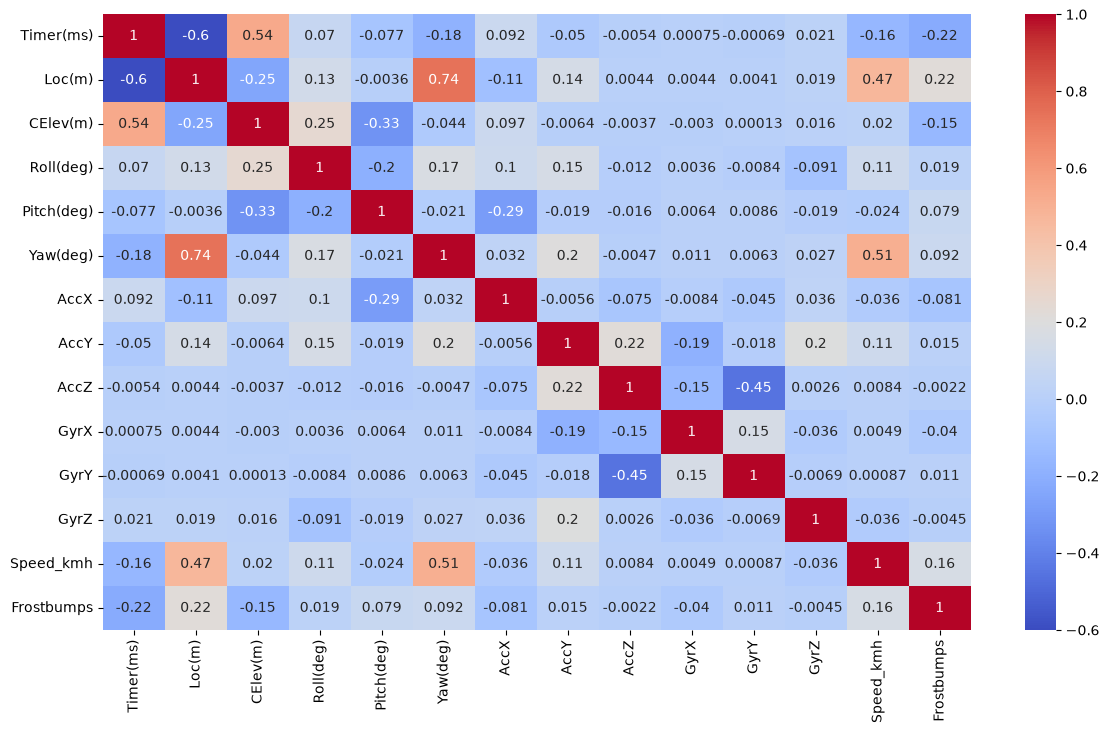

In [30]:
correlatinos = df.corr(numeric_only=True)
plt.figure(figsize=(14,8))
sns.heatmap(correlatinos, annot=True, cmap='coolwarm')

interval columns not set, guessing: ['Timer(ms)', 'Loc(m)', 'CElev(m)', 'Roll(deg)', 'Pitch(deg)', 'Yaw(deg)', 'AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'Speed_kmh', 'Frostbumps']


<Axes: >

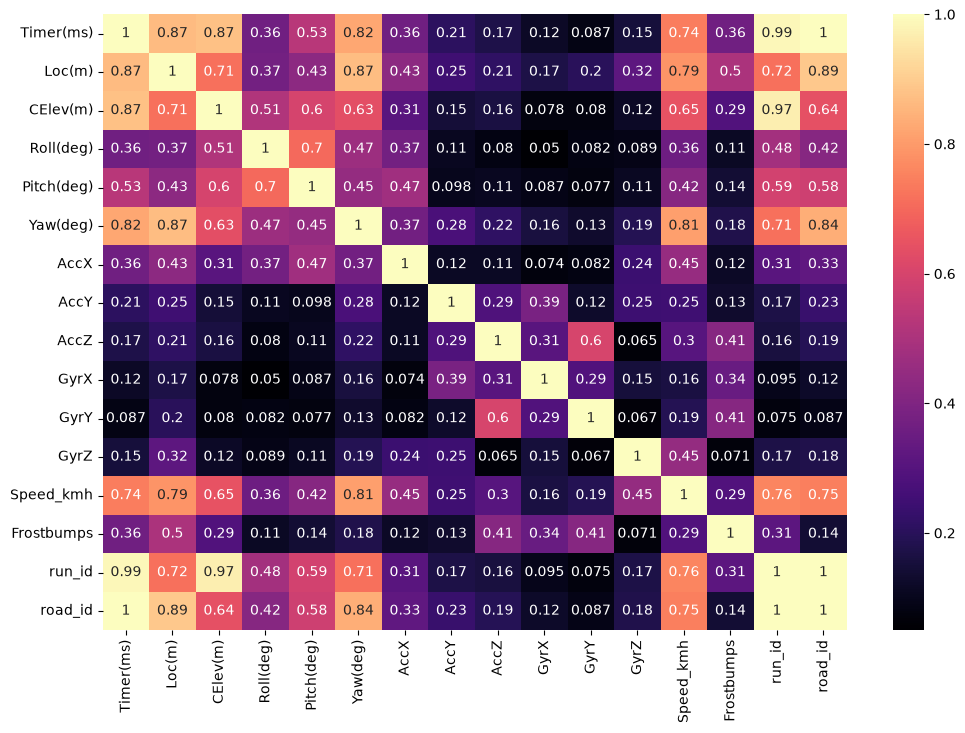

In [31]:
import phik

phik_matrix = df.phik_matrix()

plt.figure(figsize=(12,8))

sns.heatmap(phik_matrix, annot=True, cmap='magma')

In [32]:
feats = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
         "Pitch(deg)", "Roll(deg)", "Speed_kmh"]

stats = dfC1.groupby("Frostbumps")[feats].agg(["mean", "std", "min", "median", "max"])
print(stats.T)   # transposed is easier to read

Frostbumps                 0          1
AccX       mean     0.490253   0.320048
           std      0.516449   0.573071
           min     -2.311630  -2.872710
           median   0.479310   0.325095
           max      4.202160   5.295810
AccY       mean     0.058583  -0.002602
           std      0.492488   0.613048
           min     -3.469780  -4.013620
           median   0.072310  -0.008840
           max      3.194060   3.741680
AccZ       mean     9.813503   9.938401
           std      0.693116   1.855630
           min      5.013840   3.221790
           median   9.812450   9.876615
           max     15.227900  24.575690
GyrX       mean    -0.005327  -0.010001
           std      0.029214   0.050709
           min     -0.179980  -0.397290
           median  -0.005220  -0.016745
           max      0.279600   0.139680
GyrY       mean     0.000752  -0.006790
           std      0.032626   0.206710
           min     -0.306870  -0.961550
           median   0.000740  -0.000855


In [8]:
for f in ["AccZ", "GyrY"]:
    df[f + "_abs"] = df[f].abs()

print(df.groupby("Frostbumps")[["AccZ_abs", "GyrY_abs"]].describe().T)

Frostbumps                  0             1
AccZ_abs count  231411.000000  58703.000000
         mean        9.824693      9.802904
         std         0.980912      2.055455
         min         1.498380      1.286240
         25%         9.382030      8.712720
         50%         9.816780      9.808140
         75%        10.260100     10.736900
         max        19.194780     23.703130
GyrY_abs count  231411.000000  58703.000000
         mean        0.022647      0.067025
         std         0.024469      0.065916
         min         0.000000      0.000000
         25%         0.006330      0.019450
         50%         0.015310      0.045830
         75%         0.030450      0.091960
         max         0.325800      0.502450


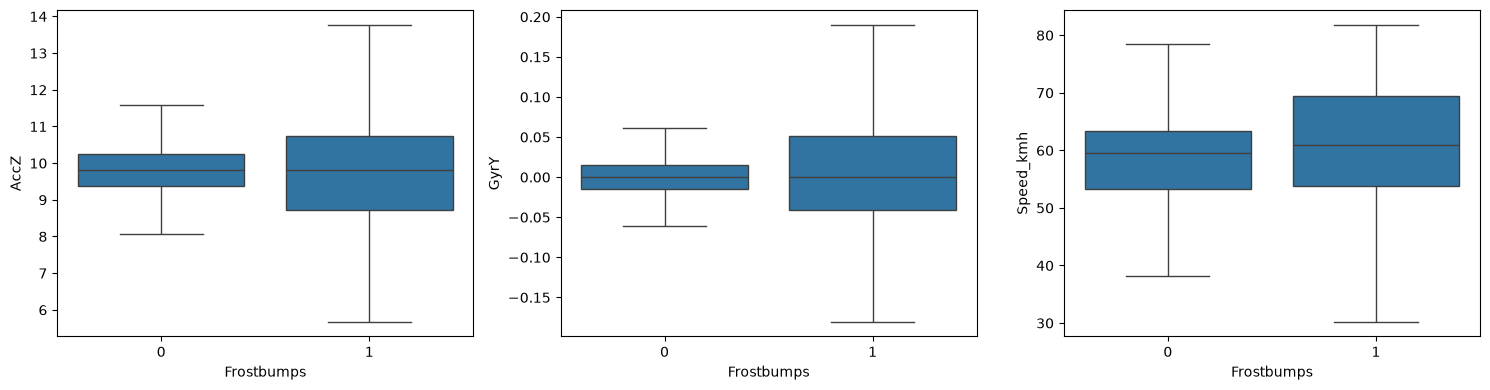

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, ["AccZ", "GyrY", "Speed_kmh"]):
    sns.boxplot(data=df, x="Frostbumps", y=f, ax=ax, showfliers=False)
plt.tight_layout()

In [10]:
print(df.groupby(["run_id", "Frostbumps"])[["AccZ_abs", "GyrY_abs"]].mean().unstack())

            AccZ_abs            GyrY_abs          
Frostbumps         0         1         0         1
run_id                                            
A1          9.822578  9.789912  0.025587  0.085073
A2          9.822005  9.781964  0.022469  0.067327
A3          9.822005  9.781964  0.022469  0.067327
B1          9.842306  9.860768  0.015051  0.063051
B2          9.854882  9.851491  0.020101  0.078647
B3          9.835840  9.846983  0.018957  0.054833
B4          9.823922  9.840382  0.019223  0.035618


In [12]:
def bump_events(d):
    flag = d["Frostbumps"].to_numpy()
    edges = np.diff(flag, prepend=0, append=0)
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
    rows = []
    for s, e in zip(starts, ends):
        seg = d.iloc[s:e]
        rows.append({
            "run_id": d["run_id"].iloc[0],
            "n_rows": len(seg),
            "length_m": seg["Loc(m)"].iloc[-1] - seg["Loc(m)"].iloc[0],
            "speed": seg["Speed_kmh"].mean(),
            "accz_peak": seg["AccZ"].abs().max(),
            "gyry_peak": seg["GyrY"].abs().max(),
            "accz_rms": np.sqrt((seg["AccZ"]**2).mean()),
        })
    return pd.DataFrame(rows)

events = pd.concat([bump_events(d) for _, d in df.groupby("run_id")], ignore_index=True)
print(events.describe())

            n_rows    length_m      speed  accz_peak  gyry_peak   accz_rms
count    41.000000   41.000000  41.000000   41.00000  41.000000  41.000000
mean   1431.780488   59.106073  63.250481   16.74367   0.280972  10.059281
std     831.237617   27.793114  11.661845    2.15366   0.089465   0.195325
min     256.000000   12.928000  37.877312   12.29693   0.142850   9.831244
25%     760.000000   36.928000  58.503367   15.75012   0.209300   9.937979
50%    1282.000000   57.975000  61.340701   16.36683   0.264250  10.010177
75%    1911.000000   81.973000  72.144498   17.67785   0.355130  10.079467
max    3933.000000  112.976000  81.753203   23.70313   0.502450  10.744820


In [16]:
df.isna().sum()

Timer(ms)     0
Loc(m)        0
CElev(m)      0
Roll(deg)     0
Pitch(deg)    0
Yaw(deg)      0
AccX          0
AccY          0
AccZ          0
GyrX          0
GyrY          0
GyrZ          0
Speed_kmh     0
Frostbumps    0
run_id        0
road_id       0
AccZ_abs      0
GyrY_abs      0
dtype: int64

In [ ]:
# Windowing per run. This version labels every row inside the window, so the model predicts a bump mask (seq-to-seq). That’s more forgiving of noisy label edges than a single label per window.

feature_cols = ["Pitch(deg)", "Roll(deg)", "AccX", "AccY", "AccZ",
                "GyrX", "GyrY", "GyrZ", "Speed_kmh"]  # adjust per earlier discussion

def make_windows(d, win=200, stride=20):
    d = d.sort_values("Timer(ms)")
    X = d[feature_cols].to_numpy(np.float32)
    y = d["Frostbumps"].to_numpy(np.float32)
    starts = range(0, len(d) - win + 1, stride)
    Xw = np.stack([X[s:s + win] for s in starts])
    yw = np.stack([y[s:s + win] for s in starts])
    return Xw, yw

data = {}
for rid, d in df.groupby("run_id"):
    data[rid] = make_windows(d)          # Xw: (n, win, F), yw: (n, win)

In [19]:
df['run_id'].value_counts()

run_id
A2    83597
A3    83597
A1    69125
B4    18128
B3    13083
B2    12985
B1     9599
Name: count, dtype: int64

In [ ]:
# Pick win from the bump lengths you got in the events table (the window should cover a bump plus context, a few times its length). Stride only controls overlap.
# Split by run, then scale on train only:

train_ids = ["A1", "A2", "A3", "B1", "B2"]
val_ids   = ["B4"]
test_ids  = ["B3"]
# C1 left out on purpose

def stack(ids):
    X = np.concatenate([data[i][0] for i in ids])
    y = np.concatenate([data[i][1] for i in ids])
    return X, y

Xtr, ytr = stack(train_ids)
Xva, yva = stack(val_ids)
Xte, yte = stack(test_ids)

mu  = Xtr.reshape(-1, Xtr.shape[-1]).mean(0)
std = Xtr.reshape(-1, Xtr.shape[-1]).std(0) + 1e-8
Xtr, Xva, Xte = [(x - mu) / std for x in (Xtr, Xva, Xte)]

In [21]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

win, F = Xtr.shape[1], Xtr.shape[2]

# Class imbalance: weight positive timesteps in the loss
pos_w = float((ytr == 0).sum() / max((ytr == 1).sum(), 1))
pos_w = min(pos_w, 50.0)  # cap it, huge weights make training unstable

def weighted_bce(y_true, y_pred):
    # y_pred are logits, shape (batch, win, 1); y_true is (batch, win)
    y_true = tf.expand_dims(tf.cast(y_true, tf.float32), -1)
    loss = tf.nn.weighted_cross_entropy_with_logits(
        labels=y_true, logits=y_pred, pos_weight=pos_w
    )
    return tf.reduce_mean(loss)

def build_model(win, F):
    inp = keras.Input(shape=(win, F))
    x = layers.Conv1D(32, 7, padding="same", activation="relu")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 7, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 7, padding="same", dilation_rate=2, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Conv1D(1, 1)(x)          # per-timestep logit
    return keras.Model(inp, out)

model = build_model(win, F)

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=weighted_bce,
    metrics=[keras.metrics.AUC(curve="PR", from_logits=True, name="pr_auc")],
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max",
                                  patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=50,
    batch_size=64,
    shuffle=True,
    callbacks=callbacks,
)

Epoch 1/50


ValueError: `logits` and `labels` must have the same shape, received ((None, 200) vs (None, 200, 1)).

Things to keep in mind:

Start simple. A 1D CNN is a good first model, and a small GRU or a U-Net-style CNN are the next steps. Also run a baseline (gradient boosting on rolling RMS and peak features) so you know whether the NN actually helps.
Evaluation: use PR-AUC and event-level precision/recall, not accuracy. With overlapping windows, average the predictions per row (or per distance bin) before counting events, otherwise one bump gets counted several times.
Label noise: consider smoothing the labels (gaussian_filter1d) before windowing, or masking a few samples around each flag boundary out of the loss.
Speed: raw Speed_kmh is fine as a feature, but a distance-grid resample makes bumps look the same at any speed and is worth trying as a second experiment.
Reproducibility: set seeds, and keep the run_id of every window if you want per-run metrics later.

Do you want me to add the event-level evaluation (stitching window predictions back into per-run signals and counting hits with a tolerance), or the distance-grid resampling first?

In [27]:
dfA1['Loc(m)'].min()

np.float64(3767.52)

In [28]:
dfA1['Loc(m)'].max()

np.float64(6937.284)

In [23]:
df.columns

Index(['Timer(ms)', 'Loc(m)', 'CElev(m)', 'Roll(deg)', 'Pitch(deg)',
       'Yaw(deg)', 'AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'Speed_kmh',
       'Frostbumps', 'run_id', 'road_id', 'AccZ_abs', 'GyrY_abs'],
      dtype='str')

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, average_precision_score

tf.keras.utils.set_random_seed(42)

# 1. Cut every run into 5 m windows, one row per window
df["window"] = (df["Loc(m)"] // 5).astype(int)

def abs_max(s):
    return s.abs().max()

table = df.groupby(["run_id", "window"]).agg(
    accx_std=("AccX", "std"),
    accy_std=("AccY", "std"),
    accz_std=("AccZ", "std"),
    accz_max=("AccZ", abs_max),
    gyrx_std=("GyrX", "std"),
    gyry_std=("GyrY", "std"),
    gyry_max=("GyrY", abs_max),
    gyrz_std=("GyrZ", "std"),
    pitch_std=("Pitch(deg)", "std"),
    speed=("Speed_kmh", "mean"),
    bump=("Frostbumps", "max"),      # 1 if any row in the window is a bump
).reset_index().dropna()

cols = ["accx_std", "accy_std", "accz_std", "accz_max", "gyrx_std",
        "gyry_std", "gyry_max", "gyrz_std", "pitch_std", "speed"]

# 2. Split by run (C1 is left out on purpose)
train = table[table["run_id"].isin(["A1", "A2", "A3", "B1", "B2"])]
val   = table[table["run_id"].isin(["B4"])]
test  = table[table["run_id"].isin(["B3"])]

# 3. Scale: learn the mean/std from TRAIN only, then apply to all three
scaler = StandardScaler().fit(train[cols])
Xtr = scaler.transform(train[cols]);  ytr = train["bump"].to_numpy()
Xva = scaler.transform(val[cols]);    yva = val["bump"].to_numpy()
Xte = scaler.transform(test[cols]);   yte = test["bump"].to_numpy()

# 4. Bumps are rare, so make each bump count more in the loss
w = min((ytr == 0).sum() / max((ytr == 1).sum(), 1), 20)
class_weight = {0: 1.0, 1: float(w)}

# 5. The neural network
model = keras.Sequential([
    layers.Input(shape=(len(cols),)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),   # output: probability of a bump
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")],
)

# 6. Train, stopping automatically when validation stops improving
model.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=100,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True)],
)

# 7. Test on the held-out run
probs = model.predict(Xte).ravel()
print("Test PR-AUC:", average_precision_score(yte, probs))
print(classification_report(yte, probs > 0.5))

Epoch 1/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0082 - pr_auc: 0.4678 - val_loss: 0.6448 - val_pr_auc: 0.4976
Epoch 2/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8357 - pr_auc: 0.6406 - val_loss: 0.6582 - val_pr_auc: 0.4706
Epoch 3/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7734 - pr_auc: 0.6714 - val_loss: 0.7019 - val_pr_auc: 0.4595
Epoch 4/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7476 - pr_auc: 0.6767 - val_loss: 0.7225 - val_pr_auc: 0.4620
Epoch 5/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7406 - pr_auc: 0.6942 - val_loss: 0.7276 - val_pr_auc: 0.4606
Epoch 6/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7228 - pr_auc: 0.6997 - val_loss: 0.7395 - val_pr_auc: 0.4724
Epoch 7/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7155 - pr_auc: 0.7095 - val_loss: 0.7524 - val_pr_auc: 0.4606
Epoch 8/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7149 - pr_auc: 0.7086 - val_loss: 0.7521 - val_pr_auc: 0.4616
Epoch 9/100
65/6

: 